In [1]:
## -- System dependencies --
import sys, os, gc
import torch

## -- Device-Agnostic (GPU/CPU) --
def get_system_info():
    if torch.cuda.is_available():
        return f"GPU: {torch.cuda.get_device_name(0)}"
    else:
        return f"CPU: {os.cpu_count()}"

get_system_info()

'GPU: Tesla T4'

In [2]:
try:
    from pytabkit import TabM_D_Classifier, RealMLP_TD_Classifier
except:
    !pip install -q pytabkit
    from pytabkit import TabM_D_Classifier, RealMLP_TD_Classifier

try:
    import xgboost as xgb
except:
    !pip install -q xgboost
    import xgboost as xgb

In [3]:
%matplotlib inline
%config InlineBackend.figure_format = 'svg'

In [4]:
## -- Data Manipulation --
import numpy as np, pandas as pd, random

## -- Visualization --
from IPython.display import display, Image
import matplotlib.pyplot as plt
import seaborn as sns

## -- Functional Tools --
import itertools
from tqdm.auto import tqdm
from time import time, sleep
from importlib.metadata import version

## -- Machine Learning --
from sklearn.calibration import CalibrationDisplay
from sklearn.model_selection import KFold, StratifiedKFold, train_test_split
from sklearn.metrics import roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.preprocessing import OrdinalEncoder, LabelEncoder, KBinsDiscretizer, TargetEncoder as skTE

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, SimpleImputer

import warnings
warnings.simplefilter('ignore')
warnings.filterwarnings('ignore')

## -- Set Configuration --
# sklearn.set_config(transform_output="pandas")
# pd.options.mode.copy_on_write = True
pd.set_option("display.max_columns", 100)
sns.set_style("whitegrid")
# plt.style.use('ggplot')

print("xgboost  version:", xgb.__version__)
print("PyTabKit version:", version("pytabkit"))

xgboost  version: 3.4.1
PyTabKit version: 1.7.3


In [5]:
TEAL, GOLD, CORAL, BLUE, DARK, CRIM, MUTED, INK, PAPER = '#168c91','#e8b44f','#dc705a',\
                                                         'dodgerblue','#0B4F7A','crimson',\
                                                         '#627D98','#102A43','#faf9f5'
plt.rcParams.update({
    'figure.facecolor': PAPER,
    'axes.facecolor': PAPER,
    'savefig.facecolor': PAPER,
    'font.family': 'DejaVu Sans',
    'font.size': 9,
    'axes.titlesize': 10,
    'axes.titleweight': 'semibold',
    'axes.labelcolor': INK,
    'text.color': INK,
    'xtick.color': DARK,
    'ytick.color': DARK,
    'axes.edgecolor': MUTED,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.color': MUTED,
    'patch.edgecolor': DARK,
    # 'patch.force_edgecolor': True,
    # 'patch.linewidth': 1.5,
    # 'figure.dpi':110,
    # 'savefig.dpi':160,
})
# CMAP = LinearSegmentedColormap.from_list('atlas', ['#f0f5ef','#a9d6ca',TEAL,INK])
sns.set_palette([TEAL, GOLD, CORAL, BLUE, MUTED, CRIM, DARK, INK, PAPER])

## -- Set Global Seed --
CFG = {
    'FOLDS':  5,
    'SEED':   42,
    'GREEN':  '\033[32m',
    'YELLOW': '\033[33m',
    'RED':    '\033[31m',
    'RESET':  '\033[0m'
}

print(f"CLASSIC {CFG['GREEN']} GREEN {CFG['RESET']} {CFG['YELLOW']} YELLOW {CFG['RESET']}")

CLASSIC  GREEN   YELLOW 


In [6]:
## -- ⚠️ IMPORTANT: SELECT PLATFORM ⚠️ --
PLATFORM = "kaggle" # -> 'colab' 'kaggle'

if PLATFORM == "kaggle":
    PATH = "/kaggle/input/competitions/playground-series-s6e10/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train = pd.read_csv(PATH+"train.csv")
    test = pd.read_csv(PATH+"test.csv")

    ORIG_PATH = "/kaggle/input/datasets/arseniyshutko/binary-aviation-satisfaction-129k/"
    orig = pd.read_csv(ORIG_PATH+"data.csv")
elif PLATFORM == "colab":
    from google.colab import drive
    drive.mount("/content/drive")

    PATH   = "/content/drive/MyDrive/-- shared_notebooks --/Ps6e10 | Airline Satisfaction/_airline_data/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    orig = pd.read_csv(PATH+"data.csv")

## =================================================================================

for (name, df) in {"Train": train, "Test": test, 'Orig': orig}.items(): #
    print(f"{name} shape: {df.shape}")

print(f"\nFrame type: {type(train)}")

Train shape: (699635, 23)
Test shape: (299844, 22)
Orig shape: (129880, 22)

Frame type: <class 'pandas.core.frame.DataFrame'>


## FEATURE ENGINEERING

In [7]:
# ## -- Cyclic encoding --
# CYCLICS = []
# cy_cols = [c for c in train.columns if c.endswith("_hours")]

# for col in tqdm(cy_cols):
#     for p in [12, 24]:
#         n_s = f"{col}_sin_{p}"

#         train[n_s] = np.sin(2 * np.pi * train[col] / p).astype('float32')
#         orig[n_s]  = np.sin(2 * np.pi * orig[col] / p).astype('float32')
#         test[n_s]  = np.sin(2 * np.pi * test[col] / p).astype('float32')
#         CYCLICS.append(n_s)

#         # n_c = f"{col}_cos_{p}"
#         # train[n_c] = np.cos(2 * np.pi * train[col] / p).astype('float32')
#         # test[n_c] = np.cos(2 * np.pi * test[col] / p).astype('float32')
#         # orig[n_c] = np.cos(2 * np.pi * orig[col] / p).astype('float32')
#         # CYCLICS.append(n_c)

# # NUMS.extend(CYCLICS)

# print(f"Cylcic Features created: {len(CYCLICS)}")
# print(train[CYCLICS].describe().T)

# train[CYCLICS].head()

In [8]:
from sklearn.base import BaseEstimator, TransformerMixin ## ===== Target/CategoryMean ENCODERS =====

class customTE(BaseEstimator, TransformerMixin):
    """
    Target Encoder that supports multiple aggregation functions,
    internal cross-validation for leakage prevention, and smoothing.

    Parameters
    ----------
    cols_to_encode : list of str
        List of column names to be target encoded.

    aggs : list of str, default=['mean']
        List of aggregation functions to apply. Any function accepted by
        pandas' `.agg()` method is supported, such as:
        'mean', 'std', 'var', 'min', 'max', 'skew', 'nunique',
        'count', 'sum', 'median'.
        Smoothing is applied only to the 'mean' aggregation.

    cv : int, default=5
        Number of folds for cross-validation in fit_transform.

    smooth : float or 'auto', default='auto'
        The smoothing parameter `m`. A larger value puts more weight on the
        global mean. If 'auto', an empirical Bayes estimate is used.

    drop_original : bool, default=False
        If True, the original columns to be encoded are dropped.
    """
    def __init__(self, cols_to_encode, aggs=['mean'], cv=5, smooth='auto', drop_original=False):
        self.cols_to_encode = cols_to_encode
        self.aggs = aggs
        self.cv = cv
        self.smooth = smooth
        self.drop_original = drop_original
        self.mappings_ = {}
        self.global_stats_ = {}

    def fit(self, X, y):
        """
        Learn mappings from the entire dataset.
        These mappings are used for the transform method on validation/test data.
        """
        temp_df = X.copy()
        temp_df['target'] = y

        # Learn global statistics for each aggregation
        for agg_func in self.aggs:
            self.global_stats_[agg_func] = y.agg(agg_func)

        # Learn category-specific mappings
        for col in self.cols_to_encode:
            self.mappings_[col] = {}
            for agg_func in self.aggs:
                mapping = temp_df.groupby(col)['target'].agg(agg_func)
                self.mappings_[col][agg_func] = mapping

        return self

    def transform(self, X):
        """
        Apply learned mappings to the data.
        Unseen categories are filled with global statistics.
        """
        X_transformed = X.copy()
        for col in tqdm(self.cols_to_encode, desc="TE encoding"):
            for agg_func in self.aggs:
                new_col_name = f"TE_{col}_{agg_func}"
                map_series = self.mappings_[col][agg_func]
                X_transformed[new_col_name] = X[col].map(map_series)
                X_transformed[new_col_name].fillna(self.global_stats_[agg_func], inplace=True)

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed

    def fit_transform(self, X, y):
        """
        Fit and transform the data using internal cross-validation to prevent leakage.
        """
        # First, fit on the entire dataset to get global mappings for transform method
        self.fit(X, y)

        # Initialize an empty DataFrame to store encoded features
        encoded_features = pd.DataFrame(index=X.index)

        kf = KFold(n_splits=self.cv, shuffle=True, random_state=42)

        for train_idx, val_idx in kf.split(X, y):
            X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
            X_val = X.iloc[val_idx]

            temp_df_train = X_train.copy()
            temp_df_train['target'] = y_train

            for col in self.cols_to_encode:
                # --- Calculate mappings only on the training part of the fold ---
                for agg_func in self.aggs:
                    new_col_name = f"TE_{col}_{agg_func}"

                    # Calculate global stat for this fold
                    fold_global_stat = y_train.agg(agg_func)

                    # Calculate category stats for this fold
                    mapping = temp_df_train.groupby(col)['target'].agg(agg_func)

                    # --- Apply smoothing only for 'mean' aggregation ---
                    if agg_func == 'mean':
                        counts = temp_df_train.groupby(col)['target'].count()

                        m = self.smooth
                        if self.smooth == 'auto':
                            # Empirical Bayes smoothing
                            variance_between = mapping.var()
                            avg_variance_within = temp_df_train.groupby(col)['target'].var().mean()
                            if variance_between > 0:
                                m = avg_variance_within / variance_between
                            else:
                                m = 0  # No smoothing if no variance between groups

                        # Apply smoothing formula
                        smoothed_mapping = (counts * mapping + m * fold_global_stat) / (counts + m)
                        encoded_values = X_val[col].map(smoothed_mapping)
                    else:
                        encoded_values = X_val[col].map(mapping)

                    # Store encoded values for the validation fold
                    encoded_features.loc[X_val.index, new_col_name] = encoded_values.fillna(fold_global_stat)

        # Merge with original DataFrame
        X_transformed = X.copy()
        for col in encoded_features.columns:
            X_transformed[col] = encoded_features[col]

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed


class CategoryMeanTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, cat_cols=None):
        self.cat_cols = cat_cols
        self.mappings_ = {}
    def fit(self, X, y):
        X = X.copy()
        if self.cat_cols is None:
            self.cat_cols = X.select_dtypes(include=['category']).columns.tolist()
        self.mappings_ = {}
        for col in self.cat_cols:
            df_temp = pd.DataFrame({col: X[col], 'y': y})
            group_means = df_temp.groupby(col, dropna=False)['y'].mean()
            sorted_categories = group_means.sort_values().index
            self.mappings_[col] = {cat: i for i, cat in enumerate(sorted_categories)}
        return self

    def transform(self, X, y=None):
        X = X.copy()
        for col, mapping in self.mappings_.items():
            if col in X.columns:
                X[col] = X[col].map(mapping)
        return X

In [9]:
def original_TE(
    orig: pd.DataFrame,
    df: pd.DataFrame,
    features: list=None,
    target: str=None,
    aggs: list=None,
    fill_nan: bool=False,
):

    if features is None or len(features) == 0:
        return df.copy()

    if aggs is None or len(aggs) == 0:
        return df.copy()

    X_df = df.copy()

    orig_cols = []
    maps = {}

    valid_features = [col for col in features if col in orig.columns]

    pbar = tqdm(valid_features)
    for col in pbar:
        for agg_ in aggs:
            agg_key = agg_.lower()
            new_col = f"oTE_{col}_{agg_key}"
            pbar.set_description(f"Augmenting {col}")
            map_key = (col, agg_key)
            if map_key not in maps:
                try:
                    if agg_key == 'mean':
                        map_df = (orig.groupby(col)[target].mean().reset_index(name=new_col))
                    elif agg_key == 'median':
                        map_df = (orig.groupby(col)[target].median().reset_index(name=new_col))
                    elif agg_key == 'count':
                        map_df = (orig.groupby(col).size().reset_index(name=new_col)) #.astype('int32')
                    elif agg_key == 'nunique':
                        map_df = (orig.groupby(col)[target].nunique().reset_index(name=new_col)) #.astype('int32')
                    elif agg_key == 'std':
                        map_df = (orig.groupby(col)[target].std().reset_index(name=new_col))
                    elif agg_key == 'skew':
                        map_df = (orig.groupby(col)[target].skew().reset_index(name=new_col))
                    elif agg_key == 'max':
                        map_df = (orig.groupby(col)[target].max().reset_index(name=new_col))
                    elif agg_key == 'min':
                        map_df = (orig.groupby(col)[target].min().reset_index(name=new_col))
                    else:
                        continue
                except Exception as e:
                    print(f"Warning: failed to create map for col={col}, agg={agg_}: {e}")
                    continue

                maps[map_key] = map_df

            map_df = maps.get(map_key)
            if map_df is None:
                continue

            # Merge maps into each split
            X_df = X_df.merge(map_df, on=col, how='left')

            orig_cols.append(new_col)

        pbar.set_description(f"Original augment complete!")

    global_mean   = orig[target].mean()
    global_median = orig[target].median()

    def fill_conditionally(df):
        for c in orig_cols:
            if c.endswith(('_mean', '_max', '_min')):
                df[c] = df[c].fillna(global_mean)
            elif c.endswith('_median'):
                df[c] = df[c].fillna(global_median)
            else:
                df[c] = df[c].fillna(0)
        return df

    if fill_nan:
        X_df = fill_conditionally(X_df)

    return X_df, orig_cols

print("-- Data augment function ready! --")

-- Data augment function ready! --


In [10]:
# FEATURES = [c for c in train.columns if c not in [ID, TARGET]]
# print("Total Features:", len(FEATURES))

# combined = pd.concat([train, test, orig])
# ## ------------------------------------------------------------
# # # -- Duplicate Nums as Cats --
# # CATS_2 = []
# # for c in tqdm(NUMS, title="nums_to_cats"):
# #     n = f"{c}_cat"
# #     combined[n] = combined[c].copy()
# #     CATS_2.append(n)
# # FEATURES.extend(CATS_2)
# ## ------------------------------------------------------------
# ## -- Factorize CATS --
# for c in tqdm(CATS, desc="factorize_cats"): # +INTER + new_cats
#     combined[c] = combined[c].factorize()[0]

# for c in tqdm(CATS, desc="categorize_cats"):
#     combined[c] = combined[c].astype("category")

# train = combined.iloc[:len(train)][FEATURES+[TARGET]]
# test  = combined.iloc[len(train):len(train)+len(test)][FEATURES]
# orig  = combined.iloc[len(train)+len(test):]

# del combined

In [11]:
ID = 'id'
TARGET = 'satisfaction'
train[TARGET] = train[TARGET].map({False: 0, True: 1})

X = train.drop([ID, TARGET], axis=1); train_id = train[ID]
y = train[TARGET]
X_test = test.drop([ID], axis=1); test_id = test[ID]

del train, test
print("X      init shape:", X.shape)
print("X_test init shape:", X_test.shape, "\n")

cat_cols = X.select_dtypes(include=['object']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object']).columns.tolist()
base_cols = cat_cols + num_cols

print("init len(cat_cols):", len(cat_cols))
print("init len(num_cols):", len(num_cols), "\n")

category_map = {}
important_combos = [
    ('Class', 'Type of Travel', 'Gender'),
    ('Class', 'Type of Travel', 'Age'),
    ('Flight Distance', 'Departure/Arrival time convenient'),
]
def feature_engineering(df, fit=False):
    # Fill NaNs
    for col in cat_cols:
        df[col] = df[col].fillna("missing")
    for col in num_cols:
        df[col] = df[col].fillna(0.0)
    
    # Categorize numericals
    for col in num_cols:
        cat_name = f"{col}_cat_"
        if fit:
            codes, uniques = df[col].factorize()
            category_map[col] = uniques
        else:
            uniques = category_map[col]
            code_map = {cat: i for i, cat in enumerate(uniques)}
            codes = df[col].map(code_map).fillna(-1).astype('int32')
        df[cat_name] = codes
        df[cat_name] = df[cat_name].astype('category')

    # Count encoding
    for col in cat_cols + ['Leg room service']:
        count_name = f"_{col}_count"
        if fit:
            count_map = df[col].value_counts()
            category_map[count_name] = count_map
        else:
            count_map = category_map[count_name]
        df[count_name] = df[col].map(count_map).fillna(0).astype('int32')

    # Create interaction categories
    combo_names = []
    for cols in important_combos:
        combo_name = '_'.join(cols) + '_'
        combo_names.append(combo_name)
        combo_series = df[cols[0]].astype(str)
        for col in cols[1:]:
            combo_series = combo_series + '_' + df[col].astype(str)
        if fit:
            codes, uniques = pd.factorize(combo_series, sort=False)
            category_map[combo_name] = uniques
        else:
            uniques = category_map[combo_name]
            code_map = {cat: i for i, cat in enumerate(uniques)}
            codes = combo_series.map(code_map).fillna(-1).astype('int32')
        df[combo_name] = codes
        df[combo_name] = df[combo_name].astype('category') 

    new_cat_cols = [col for col in df.columns if col.endswith('_')]
    new_num_cols = [col for col in df.columns if col.startswith('_')]
    return df, new_cat_cols, new_num_cols, combo_names

X, new_cat_cols, new_num_cols, combo_names = feature_engineering(X, fit=True)
X_test, _, _, _ = feature_engineering(X_test, fit=False)
cat_cols += new_cat_cols; num_cols += new_num_cols
print("len(new_cat_cols):", len(new_cat_cols))
print("len(new_num_cols):", len(new_num_cols), "\n")

print("prep len(cat_cols):", len(cat_cols))
print("prep len(num_cols):", len(num_cols), "\n")
print("X      prep shape:", X.shape)
print("X_test prep shape:", X_test.shape, "\n")

X      init shape: (699635, 21)
X_test init shape: (299844, 21) 

init len(cat_cols): 4
init len(num_cols): 17 

len(new_cat_cols): 20
len(new_num_cols): 5 

prep len(cat_cols): 24
prep len(num_cols): 22 

X      prep shape: (699635, 46)
X_test prep shape: (299844, 46) 



In [12]:
X.dtypes

Age                                                      int64
Flight Distance                                          int64
Inflight wifi service                                    int64
Departure/Arrival time convenient                        int64
Ease of Online booking                                   int64
Gate location                                            int64
Food and drink                                           int64
Online boarding                                          int64
Seat comfort                                             int64
Inflight entertainment                                   int64
On-board service                                         int64
Leg room service                                         int64
Baggage handling                                         int64
Checkin service                                          int64
Cleanliness                                              int64
Departure Delay in Minutes                             

In [13]:
X.nunique()

Age                                                      75
Flight Distance                                        3474
Inflight wifi service                                     6
Departure/Arrival time convenient                         6
Ease of Online booking                                    6
Gate location                                             6
Food and drink                                            6
Online boarding                                           6
Seat comfort                                              6
Inflight entertainment                                    6
On-board service                                          6
Leg room service                                          6
Baggage handling                                          5
Checkin service                                           6
Cleanliness                                               6
Departure Delay in Minutes                              167
Arrival Delay in Minutes                

# ML TRAINING

In [14]:
X.columns == X_test.columns

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True])

In [15]:
FOLDS = 5
skf = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=42)

USE_FULL_TRAIN = True
x_sample, x_sample2 = train_test_split(
    pd.concat([X, y], axis=1),
    train_size=100_000,
    stratify=y,
    random_state=42,
)

train_X = pd.concat([X, y], axis=1).copy() if USE_FULL_TRAIN else x_sample.reset_index(drop=True)

print(train_X.shape, type(train_X))
train_X.head()

(699635, 47) <class 'pandas.core.frame.DataFrame'>


,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,Age_cat_,Flight Distance_cat_,Inflight wifi service_cat_,Departure/Arrival time convenient_cat_,Ease of Online booking_cat_,Gate location_cat_,Food and drink_cat_,Online boarding_cat_,Seat comfort_cat_,Inflight entertainment_cat_,On-board service_cat_,Leg room service_cat_,Baggage handling_cat_,Checkin service_cat_,Cleanliness_cat_,Departure Delay in Minutes_cat_,Arrival Delay in Minutes_cat_,_Gender_count,_Customer Type_count,_Type of Travel_count,_Class_count,_Leg room service_count,Class_Type of Travel_Gender_,Class_Type of Travel_Age_,Flight Distance_Departure/Arrival time convenient_,satisfaction
0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,347952,576990,202194,327404,204124,0,0,0,0
1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,0,351683,576990,497441,342212,182369,1,1,1,1
2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,2,2,2,0,2,1,2,1,2,2,2,2,0,2,1,0,0,347952,576990,202194,327404,131580,0,2,2,0
3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,3,3,2,1,3,0,2,1,2,2,2,1,2,1,1,0,0,351683,576990,202194,327404,182369,2,3,3,0
4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,4,4,2,0,3,2,1,1,3,1,1,0,1,0,2,1,0,347952,122645,497441,327404,204124,3,4,4,0


In [16]:
_ = [c for c in train_X.columns if c not in [ID, TARGET]]
FEATURES = list(set(_))

print("Total Features:", len(FEATURES))

# train_X.head()

Total Features: 46


In [17]:
# Handle optional original table aggregations securely if flags enable them
USE_ORIGINAL = True

if USE_ORIGINAL and "original_TE" in globals():
    feats_update = FEATURES.copy()
    aggs_ = ["mean", "count"]
    X_tr, orig_cols = original_TE(
        orig, train_X, target=TARGET, features=base_cols, aggs=aggs_, fill_nan=True
    )
    x_test, _ = original_TE(
        orig, X_test, target=TARGET, features=base_cols, aggs=aggs_, fill_nan=True
    )
    feats_update.extend(orig_cols)
    X_1 = X_tr[feats_update].copy()
    y_1 = X_tr[TARGET].astype("int32")
    X_tst = x_test[feats_update].copy()
else:
    X_1 = train_X[FEATURES].copy()
    y_1 = train_X[TARGET].astype("int32")
    X_tst = X_test[FEATURES].copy()

print(X_1.shape, type(X_1))
X_1.head(3)

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

(699635, 88) <class 'pandas.core.frame.DataFrame'>


,Type of Travel,Baggage handling,Baggage handling_cat_,_Leg room service_count,On-board service,On-board service_cat_,Age,Inflight entertainment_cat_,Departure/Arrival time convenient_cat_,Cleanliness_cat_,Flight Distance_cat_,Online boarding_cat_,Age_cat_,Seat comfort_cat_,Gender,Ease of Online booking,Seat comfort,_Customer Type_count,Food and drink,Arrival Delay in Minutes,Class,Departure/Arrival time convenient,Arrival Delay in Minutes_cat_,Class_Type of Travel_Gender_,Inflight wifi service,Checkin service,Class_Type of Travel_Age_,Gate location_cat_,Gate location,Departure Delay in Minutes,Flight Distance,_Type of Travel_count,Online boarding,Ease of Online booking_cat_,Food and drink_cat_,Inflight entertainment,Flight Distance_Departure/Arrival time convenient_,Cleanliness,Leg room service_cat_,Customer Type,Inflight wifi service_cat_,Leg room service,Checkin service_cat_,Departure Delay in Minutes_cat_,_Class_count,_Gender_count,oTE_Gender_mean,oTE_Gender_count,oTE_Customer Type_mean,oTE_Customer Type_count,oTE_Type of Travel_mean,oTE_Type of Travel_count,oTE_Class_mean,oTE_Class_count,oTE_Age_mean,oTE_Age_count,oTE_Flight Distance_mean,oTE_Flight Distance_count,oTE_Inflight wifi service_mean,oTE_Inflight wifi service_count,oTE_Departure/Arrival time convenient_mean,oTE_Departure/Arrival time convenient_count,oTE_Ease of Online booking_mean,oTE_Ease of Online booking_count,oTE_Gate location_mean,oTE_Gate location_count,oTE_Food and drink_mean,oTE_Food and drink_count,oTE_Online boarding_mean,oTE_Online boarding_count,oTE_Seat comfort_mean,oTE_Seat comfort_count,oTE_Inflight entertainment_mean,oTE_Inflight entertainment_count,oTE_On-board service_mean,oTE_On-board service_count,oTE_Leg room service_mean,oTE_Leg room service_count,oTE_Baggage handling_mean,oTE_Baggage handling_count,oTE_Checkin service_mean,oTE_Checkin service_count,oTE_Cleanliness_mean,oTE_Cleanliness_count,oTE_Departure Delay in Minutes_mean,oTE_Departure Delay in Minutes_count,oTE_Arrival Delay in Minutes_mean,oTE_Arrival Delay in Minutes_count
0,Personal Travel,4,0,204124,3,0,36,0,0,0,0,0,0,0,Female,4,1,576990,1,0.0,Eco,4,0,0,4,3,0,0,3,0,694,202194,4,0,0,1,0,1,0,Loyal Customer,0,4,0,0,327404,347952,0.428975,65899,0.478115,106100,0.101326,40187,0.187673,58309,0.354726,2867,0.351852,54.0,0.600767,24775,0.388614,31880,0.531623,24444,0.347062,35717,0.199551,16051,0.623011,38468,0.223325,15108,0.141946,15675,0.318093,28542,0.583096,35886,0.480636,46761,0.450794,35453,0.196963,16729,0.45939,73356,0.47407,72753
1,Business travel,5,1,182369,5,1,56,1,1,1,1,0,1,1,Male,5,4,576990,5,0.0,Business,5,0,1,5,4,1,1,5,0,651,497441,4,1,1,5,1,3,1,Loyal Customer,1,5,1,0,342212,351683,0.440115,63981,0.478115,106100,0.583724,89693,0.694434,62160,0.572727,2310,0.331915,235.0,0.990178,14356,0.424709,27998,0.734676,17424,0.568040,17409,0.550882,27957,0.623011,38468,0.560293,39756,0.650615,31544,0.646379,29492,0.614561,30905,0.615916,33878,0.460023,36333,0.433075,30639,0.45939,73356,0.47407,72753
2,Personal Travel,4,0,131580,4,2,31,2,0,1,2,1,2,2,Female,2,3,576990,3,0.0,Eco,4,0,0,3,5,2,1,5,0,1371,202194,3,2,2,3,2,3,2,Loyal Customer,2,3,2,0,327404,347952,0.428975,65899,0.478115,106100,0.101326,40187,0.187673,58309,0.439960,2007,0.428571,63.0,0.251825,32185,0.388614,31880,0.303484,30051,0.568040,17409,0.397424,27794,0.137626,27117,0.214078,23328,0.273154,23884,0.534584,38703,0.276062,25056,0.480636,46761,0.611714,25883,0.433075,30639,0.45939,73356,0.47407,72753


In [18]:
tabm_params = {
    'random_state': 42,
    'verbosity': 2,
    'val_metric_name': '1-auc_ovr',
    
    'arch_type': 'tabm-mini', # d='tabm'
    'num_emb_type': 'pwl', # d=None
    # 'allow_amp': True,
    'tabm_k': 16, # d=32

    'lr': 0.003, # d=0.002
    'n_epochs': 3,
    'patience': 2,

    'batch_size': 'auto', # d='auto'
    'd_block': 512,
    'n_blocks': 3,

    'd_embedding': 16,
    'dropout': 0.1,
    'num_emb_n_bins': 8, # d=48

    # 'compile_model': False,
    # 'gradient_clipping_norm': None,
    # 'tfms': ['quantile_tabr'],
    # 'weight_decay': 0.0,
}

tabm_params

{'random_state': 42,
 'verbosity': 2,
 'val_metric_name': '1-auc_ovr',
 'arch_type': 'tabm-mini',
 'num_emb_type': 'pwl',
 'tabm_k': 16,
 'lr': 0.003,
 'n_epochs': 3,
 'patience': 2,
 'batch_size': 'auto',
 'd_block': 512,
 'n_blocks': 3,
 'd_embedding': 16,
 'dropout': 0.1,
 'num_emb_n_bins': 8}

In [19]:
core_params = {
    "objective": "binary:logistic",
    "eval_metric": "auc",
    "enable_categorical": True,
    "verbosity": 0,
    "tree_method": 'hist',
    "device": "cuda" if torch.cuda.is_available() else "cpu",
}

gbt_params = core_params | {}
los_params = core_params | {'grow_policy': "lossguide"}
gra_params = core_params | {'sampling_method': "gradient_based"}

xgb_params = {
    'gbt': ("XGBgbt", gbt_params),
    'los': ("XGBlos", los_params),
    'gra': ("XGBgra", gra_params),
}

xgb_params

{'gbt': ('XGBgbt',
  {'objective': 'binary:logistic',
   'eval_metric': 'auc',
   'enable_categorical': True,
   'verbosity': 0,
   'tree_method': 'hist',
   'device': 'cuda'}),
 'los': ('XGBlos',
  {'objective': 'binary:logistic',
   'eval_metric': 'auc',
   'enable_categorical': True,
   'verbosity': 0,
   'tree_method': 'hist',
   'device': 'cuda',
   'grow_policy': 'lossguide'}),
 'gra': ('XGBgra',
  {'objective': 'binary:logistic',
   'eval_metric': 'auc',
   'enable_categorical': True,
   'verbosity': 0,
   'tree_method': 'hist',
   'device': 'cuda',
   'sampling_method': 'gradient_based'})}

In [20]:
## -- Pseudo Trainer --
m1_name = "TabM"
m_id = 'gra'  # "gbt", "los", "gra"
m2_name = xgb_params[m_id][0]

USE_TE  = True
DROP_TE = True

oof_preds  = np.zeros(len(X_1))
test_preds = np.zeros(len(X_tst))

fold_scores = []
m1_scores   = []
feat_importances = []

t0 = time()

## -- Initiate Training --
for idx, (train_idx, val_idx) in enumerate(skf.split(X_1, y_1), 1):
    print(f"\n{'#'*30}")
    print(f"+++ FOLD {idx}/{skf.n_splits} | ⚡️ {m2_name}-{m1_name}")
    print(f"{'#'*30}")

    X_train, X_valid = X_1.iloc[train_idx], X_1.iloc[val_idx]
    y_train, y_valid = y_1.iloc[train_idx], y_1.iloc[val_idx]
    X_test_fold = X_tst.copy()

    # ## -- OPTION A: Concatenate original data --
    # X_train = pd.concat([X_train, orig[FEATURES]], ignore_index=True)
    # y_train = pd.concat([y_train, orig[TARGET]], ignore_index=True)
    # y_train = np.concatenate([y_train, orig[TARGET].values], axis=0)

    if USE_TE:
        te_cols = combo_names
        # custom TE
        # print(f" ⧗ custom TE ({len(te_cols)}) features", end=" | ")
        # te_enc  = customTE(te_cols, cv=5, smooth='auto', aggs=['mean'], drop_original=DROP_TE)
        # X_train = te_enc.fit_transform(X_train, y_train)
        # X_valid = te_enc.transform(X_valid)
        # X_test_fold = te_enc.transform(X_test_fold)

        # sklearn TE
        print(f" ⧗ sklearn TE ({len(te_cols)}) features")
        te_enc = skTE(target_type='binary', cv=5, smooth='auto', random_state=42)
        tr_enc = te_enc.fit_transform(X_train[te_cols], y_train)
        va_enc = te_enc.transform(X_valid[te_cols])
        ts_enc = te_enc.transform(X_test_fold[te_cols])

        te_names = [f"TE_{col}_" for col in te_cols]
        X_train[te_names]  = tr_enc
        X_valid[te_names] = va_enc
        X_test_fold[te_names] = ts_enc

        combos_to_drop = [
            'Class_Type of Travel_Age_',
            'Flight Distance_Departure/Arrival time convenient_',
        ]
        X_train = X_train.drop(columns=combos_to_drop)
        X_valid = X_valid.drop(columns=combos_to_drop)
        X_test_fold = X_test_fold.drop(columns=combos_to_drop)

    # # ---- Imputing ----
    # # imputer = IterativeImputer(max_iter=20, tol=1e-3, random_state=0) # n_nearest_features=10, 
    # imputer = SimpleImputer(strategy="median")
    # X_train[all_nums] = imputer.fit_transform(X_train[all_nums], y_train)
    # X_valid[all_nums] = imputer.transform(X_valid[all_nums])
    # X_test[all_nums]  = imputer.transform(X_test[all_nums])

    # cme_encoder = CategoryMeanTransformer(cat_cols=new_cats)
    # X_train = cme_encoder.fit_transform(X_train, y_train)
    # X_valid = cme_encoder.transform(X_valid)
    # X_test  = cme_encoder.transform(X_test)

    all_cats = [c for c in cat_cols if c not in combos_to_drop]

    ## -- Select base model --
    model_1 = TabM_D_Classifier(**tabm_params)

    model_1.fit(X_train, y_train, X_valid, y_valid) #, cat_col_names=all_cats
    oof_m1  = model_1.predict_proba(X_valid)[:, 1]
    test_m1 = model_1.predict_proba(X_test_fold)[:, 1]

    score_m1 = roc_auc_score(y_valid, oof_m1)
    print(f"{CFG['YELLOW']} • {m1_name} AUC: {score_m1:.6f}{CFG['RESET']}")
    m1_scores.append(score_m1)
        
    print(f"train= {X_train.shape}, valid= {X_valid.shape}")
    if idx == 1: display(X_train.head(3))

    ## -- Pseudo labels from model_1 as features for model_2 --
    X_train_full = pd.concat([X_train, X_valid, X_test_fold])
    y_train_full = np.concatenate([y_train.to_numpy(), oof_m1, test_m1], axis=0)

    for c in cat_cols[:4]:
        X_train_full[c] = X_train_full[c].astype('category')

    X_valid_2 = X_train_full.iloc[len(X_train):len(X_train)+len(X_valid)]
    X_test_2  = X_train_full.iloc[len(X_train)+len(X_valid):]

    dtrain = xgb.DMatrix(X_train_full, y_train_full, enable_categorical=True)
    dval   = xgb.DMatrix(X_valid_2, y_valid, enable_categorical=True)
    dtest  = xgb.DMatrix(X_test_2, enable_categorical=True)

    # -------------------------------------------------------------------------
    seeder = 42 # + (idx-1)
    if m_id == 'gbt':
        use_params = {
            # GBDT ---
            'max_depth': 8,
            'subsample': 0.871,
            'colsample_bytree': 0.371,
            'min_child_weight': 19,
            'reg_alpha': 0.0018013055409110675,
            'reg_lambda': 7.891187596933341e-07,
            'gamma': 1.2606877093584014e-08,
        }
    elif m_id == 'los':
        use_params = {
            # LOSS ---
            'max_depth': 0,
            'max_leaves': 126, # increase in optuna ⚠️
            'subsample': 0.637,
            'colsample_bytree': 0.919,
            'min_child_weight': 47, # increase in optuna ⚠️
            'reg_alpha': 0.00032132892047415746,
            'reg_lambda': 2.572993871356861e-08,
            'gamma': 0.0010303560661436676,
        }
    else:
        use_params = {
            # GRADIENT ---
            'max_depth': 10, # increase in optuna ⚠️
            'subsample': 0.589,
            'colsample_bytree': 0.597,
            'min_child_weight': 23,
            'reg_alpha': 1.1166077787987638e-05,
            'reg_lambda': 0.00011563663871479361,
            'gamma': 2.5305201567863063e-07,
        }

    m2_params = xgb_params[m_id][1].copy()
    m2_params.update(
        {
            'learning_rate': 0.01,
            'random_state': seeder
        } | use_params
    )
    # -------------------------------------------------------------------------
    model_2 = xgb.train(
        m2_params,
        dtrain,
        num_boost_round=10_000,
        evals=[(dtrain, "train"), (dval, "valid")],
        early_stopping_rounds=150,
        verbose_eval=1000,
    )
    imp_dict = model_2.get_score(importance_type='gain')
    imp_values = [imp_dict.get(feat, 0.0) for feat in X_train_full.columns]
    feat_importances.append(np.asarray(imp_values))
    val_preds = model_2.predict(dval, iteration_range=(0, model_2.best_iteration+1))
    fold_test_preds = model_2.predict(dtest, iteration_range=(0, model_2.best_iteration+1))
    # -------------------------------------------------------------------------
    # model_2 = xgb.XGBClassifier(**m2_params)
    # model_2.fit(
    #     X_train_full, y_train_full, verbose=500,
    #     eval_set = [(X_valid_2, y_valid)], # (X_train_full, y_train_full), 
    #     # base_margin = trn_margin,
    #     # base_margin_eval_set=[trn_margin, val_margin],
    # )
    # feat_importances.append(np.asarray(model_2.feature_importances_))
    # val_preds = model_2.predict_proba(X_valid_2)[:, 1]
    # fold_test_preds = model.predict_proba(X_test_2)[:, 1]
    # -------------------------------------------------------------------------

    oof_preds[val_idx] = val_preds
    test_preds += fold_test_preds / FOLDS

    score_m2 = roc_auc_score(y_valid, val_preds)
    fold_scores.append(score_m2)

    print(f"{CFG['YELLOW']} • {m2_name} AUC: {score_m2:.6f}{CFG['RESET']}")

    if score_m2 >= score_m1:
        print(f"{CFG['GREEN']} • 🍀 improved: {score_m2-score_m1:.6f}{CFG['RESET']}")
    else:
        print(f"{CFG['RED']} • ⚠️ declined: {score_m1-score_m2:.6f}{CFG['RESET']}")

    # gc.collect()
    torch.cuda.empty_cache()

model_name = f"{m2_name}-{m1_name}" + f"({X_train_full.shape[1]})"
features_used = X_train_full.columns

print('\n'+'='*50)
print(f"{FOLDS}-FOLD CV: {model_name} | shape: {X_train_full.shape}")
print('='*50)

## -- CV results --
m1_fold_results = {}
m2_fold_results = {}
for i, (s1, s2) in enumerate(zip(m1_scores, fold_scores), 1):  
    print(f" • Fold {i} AUC: {m1_name}={s1:.6f} | {m2_name}={s2:.6f}")
    m1_fold_results[f"fold_{i}"] = s1
    m2_fold_results[f"fold_{i}"] = s2

oof_auc = np.round(roc_auc_score(y_1, oof_preds), 6)
avg_auc = np.round(np.mean(fold_scores), 6)
std_auc = np.round(np.std(fold_scores), 6)

m1avg_auc = np.round(np.mean(m1_scores), 6)
m1std_auc = np.round(np.std(m1_scores), 6)

print(f"{'-'*50}")
print(f"AVG AUC({m1_name})  : {m1avg_auc} ± {m1std_auc}")
print(f"AVG AUC({m2_name}): {avg_auc:} ± {std_auc}")
print(f"OOF AUC({m2_name}): {oof_auc:}")
print(f"{'-'*50}")

t1 = time()
tt = (t1-t0) / 60
print(f"{tt:.2f} mins")

del X_train_full, y_train_full, X_train, X_valid, y_train, y_valid, X_valid_2, X_test_2
del dtrain, dval, dtest, model_1, model_2


##############################
+++ FOLD 1/5 | ⚡️ XGBgra-TabM
##############################
 ⧗ sklearn TE (3) features
Columns classified as continuous: ['Baggage handling', '_Leg room service_count', 'On-board service', 'Age', 'Ease of Online booking', 'Seat comfort', '_Customer Type_count', 'Food and drink', 'Arrival Delay in Minutes', 'Departure/Arrival time convenient', 'Inflight wifi service', 'Checkin service', 'Gate location', 'Departure Delay in Minutes', 'Flight Distance', '_Type of Travel_count', 'Online boarding', 'Inflight entertainment', 'Cleanliness', 'Leg room service', '_Class_count', '_Gender_count', 'oTE_Gender_mean', 'oTE_Gender_count', 'oTE_Customer Type_mean', 'oTE_Customer Type_count', 'oTE_Type of Travel_mean', 'oTE_Type of Travel_count', 'oTE_Class_mean', 'oTE_Class_count', 'oTE_Age_mean', 'oTE_Age_count', 'oTE_Flight Distance_mean', 'oTE_Flight Distance_count', 'oTE_Inflight wifi service_mean', 'oTE_Inflight wifi service_count', 'oTE_Departure/Arrival time con

Epoch 0: 100%|██████████| 547/547 [01:00<00:00,  9.08it/s]


(val) -0.0394
🌸 New best epoch! 🌸



Epoch 1: 100%|██████████| 547/547 [01:01<00:00,  8.91it/s]


(val) -0.0392
🌸 New best epoch! 🌸



...

(val) -0.0396
🌸 New best epoch! 🌸



Epoch 1: 100%|██████████| 547/547 [01:01<00:00,  8.93it/s]


(val) -0.0397



Epoch 2: 100%|██████████| 547/547 [01:01<00:00,  8.94it/s]


(val) -0.0403



Result:
{'val': -0.03963589668273926, 'epoch': 0}
Restoring best model
 • TabM AUC: 0.960364
train= (559708, 89), valid= (139927, 89)
[0]	train-auc:0.95234	valid-auc:0.95436
[1000]	train-auc:0.96307	valid-auc:0.96053
[1789]	train-auc:0.96511	valid-auc:0.96064
 • XGBgra AUC: 0.960641
 • 🍀 improved: 0.000277

5-FOLD CV: XGBgra-TabM(89) | shape: (999479, 89)
 • Fold 1 AUC: TabM=0.960835 | XGBgra=0.961003
 • Fold 2 AUC: TabM=0.959560 | XGBgra=0.959913
 • Fold 3 AUC: TabM=0.961006 | XGBgra=0.961495
 • Fold 4 AUC: TabM=0.960447 | XGBgra=0.960859
 • Fold 5 AUC: TabM=0.960364 | XGBgra=0.960641
--------------------------------------------------
AVG AUC(TabM)  : 0.960443 ± 0.000501
AVG AUC(XGBgra): 0.960782 ± 0.000517
OOF AUC(XGBgra): 0.960663
--------------------------------------------------
26.57 mins


In [21]:
# ------------------------------------- 100K samples

# ============================================= tabm
# 5-FOLD CV: XGBgbt/TabM(47) | shape: (399844, 47)
# ==================================================
#  • Fold 1 AUC: TabM=0.956769 | XGBgbt=0.957513
#  • Fold 2 AUC: TabM=0.956594 | XGBgbt=0.956883
#  • Fold 3 AUC: TabM=0.959028 | XGBgbt=0.959210
#  • Fold 4 AUC: TabM=0.958267 | XGBgbt=0.958399
#  • Fold 5 AUC: TabM=0.957219 | XGBgbt=0.957574
# --------------------------------------------------
# AVG AUC(TabM)  : 0.957575 ± 0.000931
# AVG AUC(XGBgbt): 0.957916 ± 0.000807
# OOF AUC(XGBgbt): 0.957851
# --------------------------------------------------
# 4.88 mins

# ======================================== tabm-mini 🔥
# 5-FOLD CV: XGBgbt/TabM(47) | shape: (399844, 47)
# ==================================================
#  • Fold 1 AUC: TabM=0.956277 | XGBgbt=0.957466
#  • Fold 2 AUC: TabM=0.956641 | XGBgbt=0.957162
#  • Fold 3 AUC: TabM=0.958665 | XGBgbt=0.959323
#  • Fold 4 AUC: TabM=0.958279 | XGBgbt=0.958454
#  • Fold 5 AUC: TabM=0.956826 | XGBgbt=0.957640
# --------------------------------------------------
# AVG AUC(TabM)  : 0.957338 ± 0.000951
# AVG AUC(XGBgbt): 0.958009 ± 0.000784
# OOF AUC(XGBgbt): 0.957965
# --------------------------------------------------
# 5.16 mins

# ====================================== tabm-normal
# 5-FOLD CV: XGBgbt/TabM(47) | shape: (399844, 47)
# ==================================================
#  • Fold 1 AUC: TabM=0.956769 | XGBgbt=0.957513
#  • Fold 2 AUC: TabM=0.956594 | XGBgbt=0.956883
#  • Fold 3 AUC: TabM=0.959028 | XGBgbt=0.959210
#  • Fold 4 AUC: TabM=0.958267 | XGBgbt=0.958399
#  • Fold 5 AUC: TabM=0.957219 | XGBgbt=0.957574
# --------------------------------------------------
# AVG AUC(TabM)  : 0.957575 ± 0.000931
# AVG AUC(XGBgbt): 0.957916 ± 0.000807
# OOF AUC(XGBgbt): 0.957851
# --------------------------------------------------
# 4.88 mins

In [22]:
# ==================================================
# 5-FOLD CV: XGBgra/TabM | shape: (999479, 47)
# ==================================================
#  • Fold 1 AUC: TabM=0.960657 | XGBgra=0.960667
#  • Fold 2 AUC: TabM=0.959420 | XGBgra=0.959593
#  • Fold 3 AUC: TabM=0.961104 | XGBgra=0.961241
#  • Fold 4 AUC: TabM=0.960472 | XGBgra=0.960517
#  • Fold 5 AUC: TabM=0.960401 | XGBgra=0.960497
# ==================================================
# | PSUEDO OOF AUC: 0.96048
# | PSUEDO AVG AUC: 0.960503 ± 0.000529
# | TabM            0.960411 ± 0.000553
# ==================================================

# Training time: 23.36 mins ++++++++++++++++++++++++

In [29]:
n = f"{model_name}_{str(avg_auc).split('.')[1]}"

m1_df = pd.DataFrame.from_dict(m1_fold_results, orient='index', columns=['tabm_auc'])
m2_df = pd.DataFrame.from_dict(m2_fold_results, orient='index', columns=['pseudo_auc'])
print(pd.concat([m1_df, m2_df], axis=1).to_string())

print(f"{'-'*40}")
print(f"AVG AUC({m1_name})  : {m1avg_auc} ± {m1std_auc}")
print(f"AVG AUC({n}): {avg_auc:} ± {std_auc}")
print(f"{'-'*40}")

print(f"{tt:.2f} mins")

        tabm_auc  pseudo_auc
fold_1  0.960835    0.961003
fold_2  0.959560    0.959913
fold_3  0.961006    0.961495
fold_4  0.960447    0.960859
fold_5  0.960364    0.960641
----------------------------------------
AVG AUC(TabM)  : 0.960443 ± 0.000501
AVG AUC(XGBgra-TabM(89)_960782): 0.960782 ± 0.000517
----------------------------------------
26.57 mins


## SUBMISSION

In [30]:
## -- Save submission file --
submit[TARGET] = test_preds

submit.to_csv(f"submit_{n}.csv", index=False)
np.save(f"oof_{n}.npy", oof_preds)
np.save(f"test_{n}.npy", test_preds)

submit

,id,satisfaction
0,699635,0.214189
1,699636,0.858937
2,699637,0.922445
3,699638,0.061573
4,699639,0.047389
...,...,...
299839,999474,0.045401
299840,999475,0.034778
299841,999476,0.254144
299842,999477,0.023882


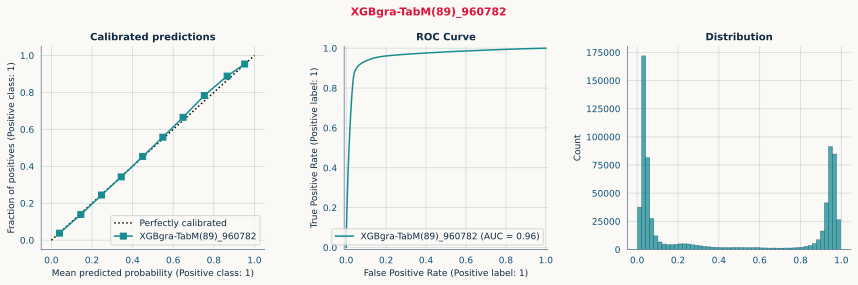

In [26]:
## -- Plot predictions errors --
_, axs = plt.subplots(1, 3, figsize=(12, 4))

CalibrationDisplay.from_predictions(y_1, oof_preds, n_bins=10, name=n, ax=axs[0])
axs[0].set_title("Calibrated predictions")

RocCurveDisplay.from_predictions(y_1, oof_preds, name=n, ax=axs[1])
axs[1].set_title("ROC Curve")
# axs[1].grid(False)

sns.histplot(oof_preds, ax=axs[2], bins=50)
axs[2].set_title("Distribution")

plt.suptitle(n, weight='bold', color=CRIM)
plt.tight_layout()
plt.show()

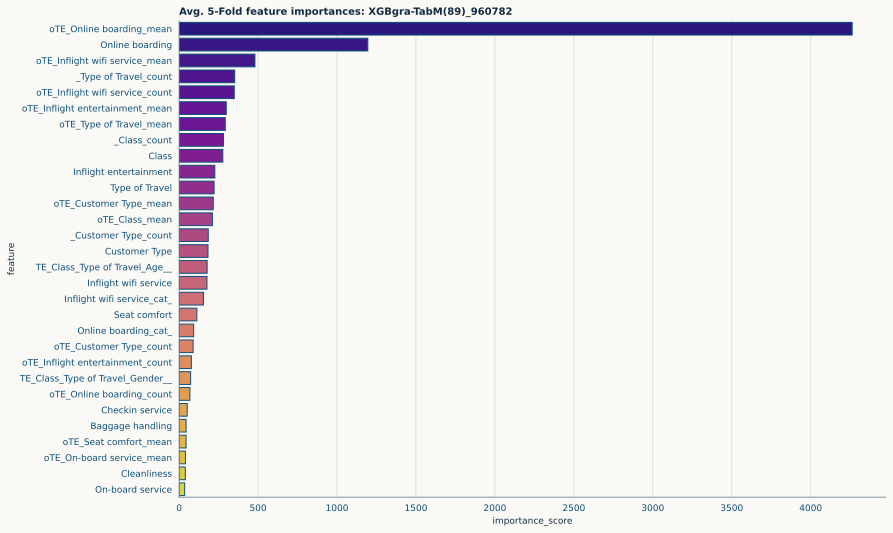

In [27]:
## -- Get feature importances --
top_n = 30
    
fi_df = pd.DataFrame(
    {
        "feature": features_used,
        "importance_score": np.mean(feat_importances, axis=0),
    }
).sort_values(by="importance_score", ascending=False).reset_index(drop=True)

plt.figure(figsize=(12.5, top_n*0.25))
sns.barplot(data=fi_df.head(top_n), x="importance_score", y="feature", palette='plasma')
plt.title(f"Avg. {FOLDS}-Fold feature importances: {n}", weight="semibold", loc='left')

plt.tight_layout()
plt.show()

print()

In [28]:
# !rm -r /kaggle/working